# 01 — Data QC

Merged RSV-A/B GISAID set: counts, sequence length, ambiguous bases, collection date, and geography. Justifies the QC filter.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath("../src"))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 120)
from rsv import io, composition


In [2]:
seqs = io.read_fasta("../data/full/RSV_full.fasta")
meta = io.load_metadata("../data/full/RSV_full_metadata.tsv")
print("sequences:", len(seqs), "| metadata rows:", len(meta))
meta[["Subtype","year","region"]].describe(include="all")

sequences: 33040 | metadata rows: 33040


,Subtype,year,region
count,33040,33040.000000,33040
unique,2,NaN,6
top,B,NaN,Europe
freq,17582,NaN,14197
mean,NaN,2022.267282,NaN
std,NaN,3.240805,NaN
min,NaN,2001.000000,NaN
25%,NaN,2021.000000,NaN
50%,NaN,2023.000000,NaN
75%,NaN,2025.000000,NaN


### Sequence length by subtype

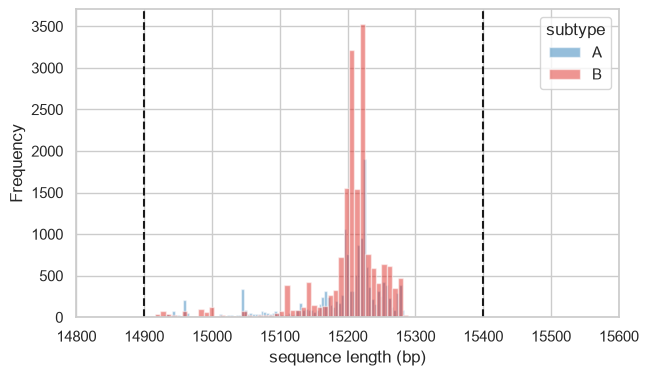

In [3]:
meta["len"] = meta["Sequence Length"]
fig, ax = plt.subplots(figsize=(7,4))
for s,c in zip("AB",["#2c7fb8","#de2d26"]):
    meta.loc[meta.Subtype==s,"len"].plot.hist(bins=120, alpha=.5, ax=ax, label=s, color=c)
ax.set_xlim(14800,15600); ax.axvline(14900,ls="--",c="k"); ax.axvline(15400,ls="--",c="k")
ax.set_xlabel("sequence length (bp)"); ax.legend(title="subtype"); plt.show()

### Apply the QC filter

In [4]:
clean, report = io.qc_filter(meta, seqs)
pd.Series(report)

input             33040
with_sequence     33040
pass_length       33039
pass_ambiguity    33038
pass_date         33038
dtype: int64

### Sequences per year and region (QC-passing)

In [5]:
display(clean.groupby(["year"]).size().rename("n").to_frame().T)
clean.groupby(["region","Subtype"]).size().unstack(fill_value=0)

year,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
n,2,4,1,9,7,14,11,22,36,128,...,886,1461,2253,1141,2392,3356,4695,5611,6319,2960


Subtype,A,B
region,,
Africa,2039,1482
Asia,1180,1200
Europe,5425,8771
North America,3024,2704
Oceania,2389,2446
South America,1401,977
